In [1]:
import pandas as pd

# URL to a reliable public raw version of the Analytics Vidhya Loan Prediction training dataset
url = 'https://raw.githubusercontent.com/subashgandyer/datasets/master/loan_train.csv'

# Load the dataset directly into a pandas DataFrame
try:
    df = pd.read_csv(url)
    print("Dataset successfully loaded from URL.")
except Exception as e:
    print(f"Error loading dataset: {e}")
    # Fallback dataset URL if needed
    fallback_url = 'https://raw.githubusercontent.com/shrikant-temburwar/Loan-Prediction-Dataset/master/train.csv'
    df = pd.read_csv(fallback_url)
    print("Dataset successfully loaded from fallback URL.")

# Display the first few rows
print("\n--- First 5 Rows of the Dataset ---")
display(df.head())

# Display shape, column names, and basic information
print("\n--- Dataset Shape ---")
print(df.shape)

print("\n--- Dataset Info ---")
df.info()

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

Dataset successfully loaded from URL.

--- First 5 Rows of the Dataset ---


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



--- Dataset Shape ---
(614, 13)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

--- Missing Values Count ---
Loan_ID               0
Gen

**Reasoning**:
Perform data cleaning and imputation on the loaded DataFrame according to the instructions, and verify that there are no remaining missing values.



In [2]:
import numpy as np

# 1. Impute categorical columns using their modes
cat_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']
for col in cat_cols:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)

# 2. Impute numerical columns using their medians
num_cols = ['LoanAmount', 'Loan_Amount_Term']
for col in num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# 3. Impute Credit_History missing values with -1.0 to treat it as a distinct category
df['Credit_History'] = df['Credit_History'].fillna(-1.0)

# 4. Drop the 'Loan_ID' column
if 'Loan_ID' in df.columns:
    df = df.drop(columns=['Loan_ID'])

# 5. Verify and print missing value counts
print("--- Missing Values Count After Cleaning and Imputation ---")
print(df.isnull().sum())

print("\n--- First 5 Rows of the Cleaned DataFrame ---")
display(df.head())


--- Missing Values Count After Cleaning and Imputation ---
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

--- First 5 Rows of the Cleaned DataFrame ---


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## Data Cleaning and Imputation

### Subtask:
Impute missing values and clean the dataset by handling missing values in categorical and numerical columns, and dropping the Loan_ID column.


**Reasoning**:
I will create a python code block to generate 5 visualizations exploring relationships with Loan_Status as instructed, including count plots, box plots, and a correlation heatmap.



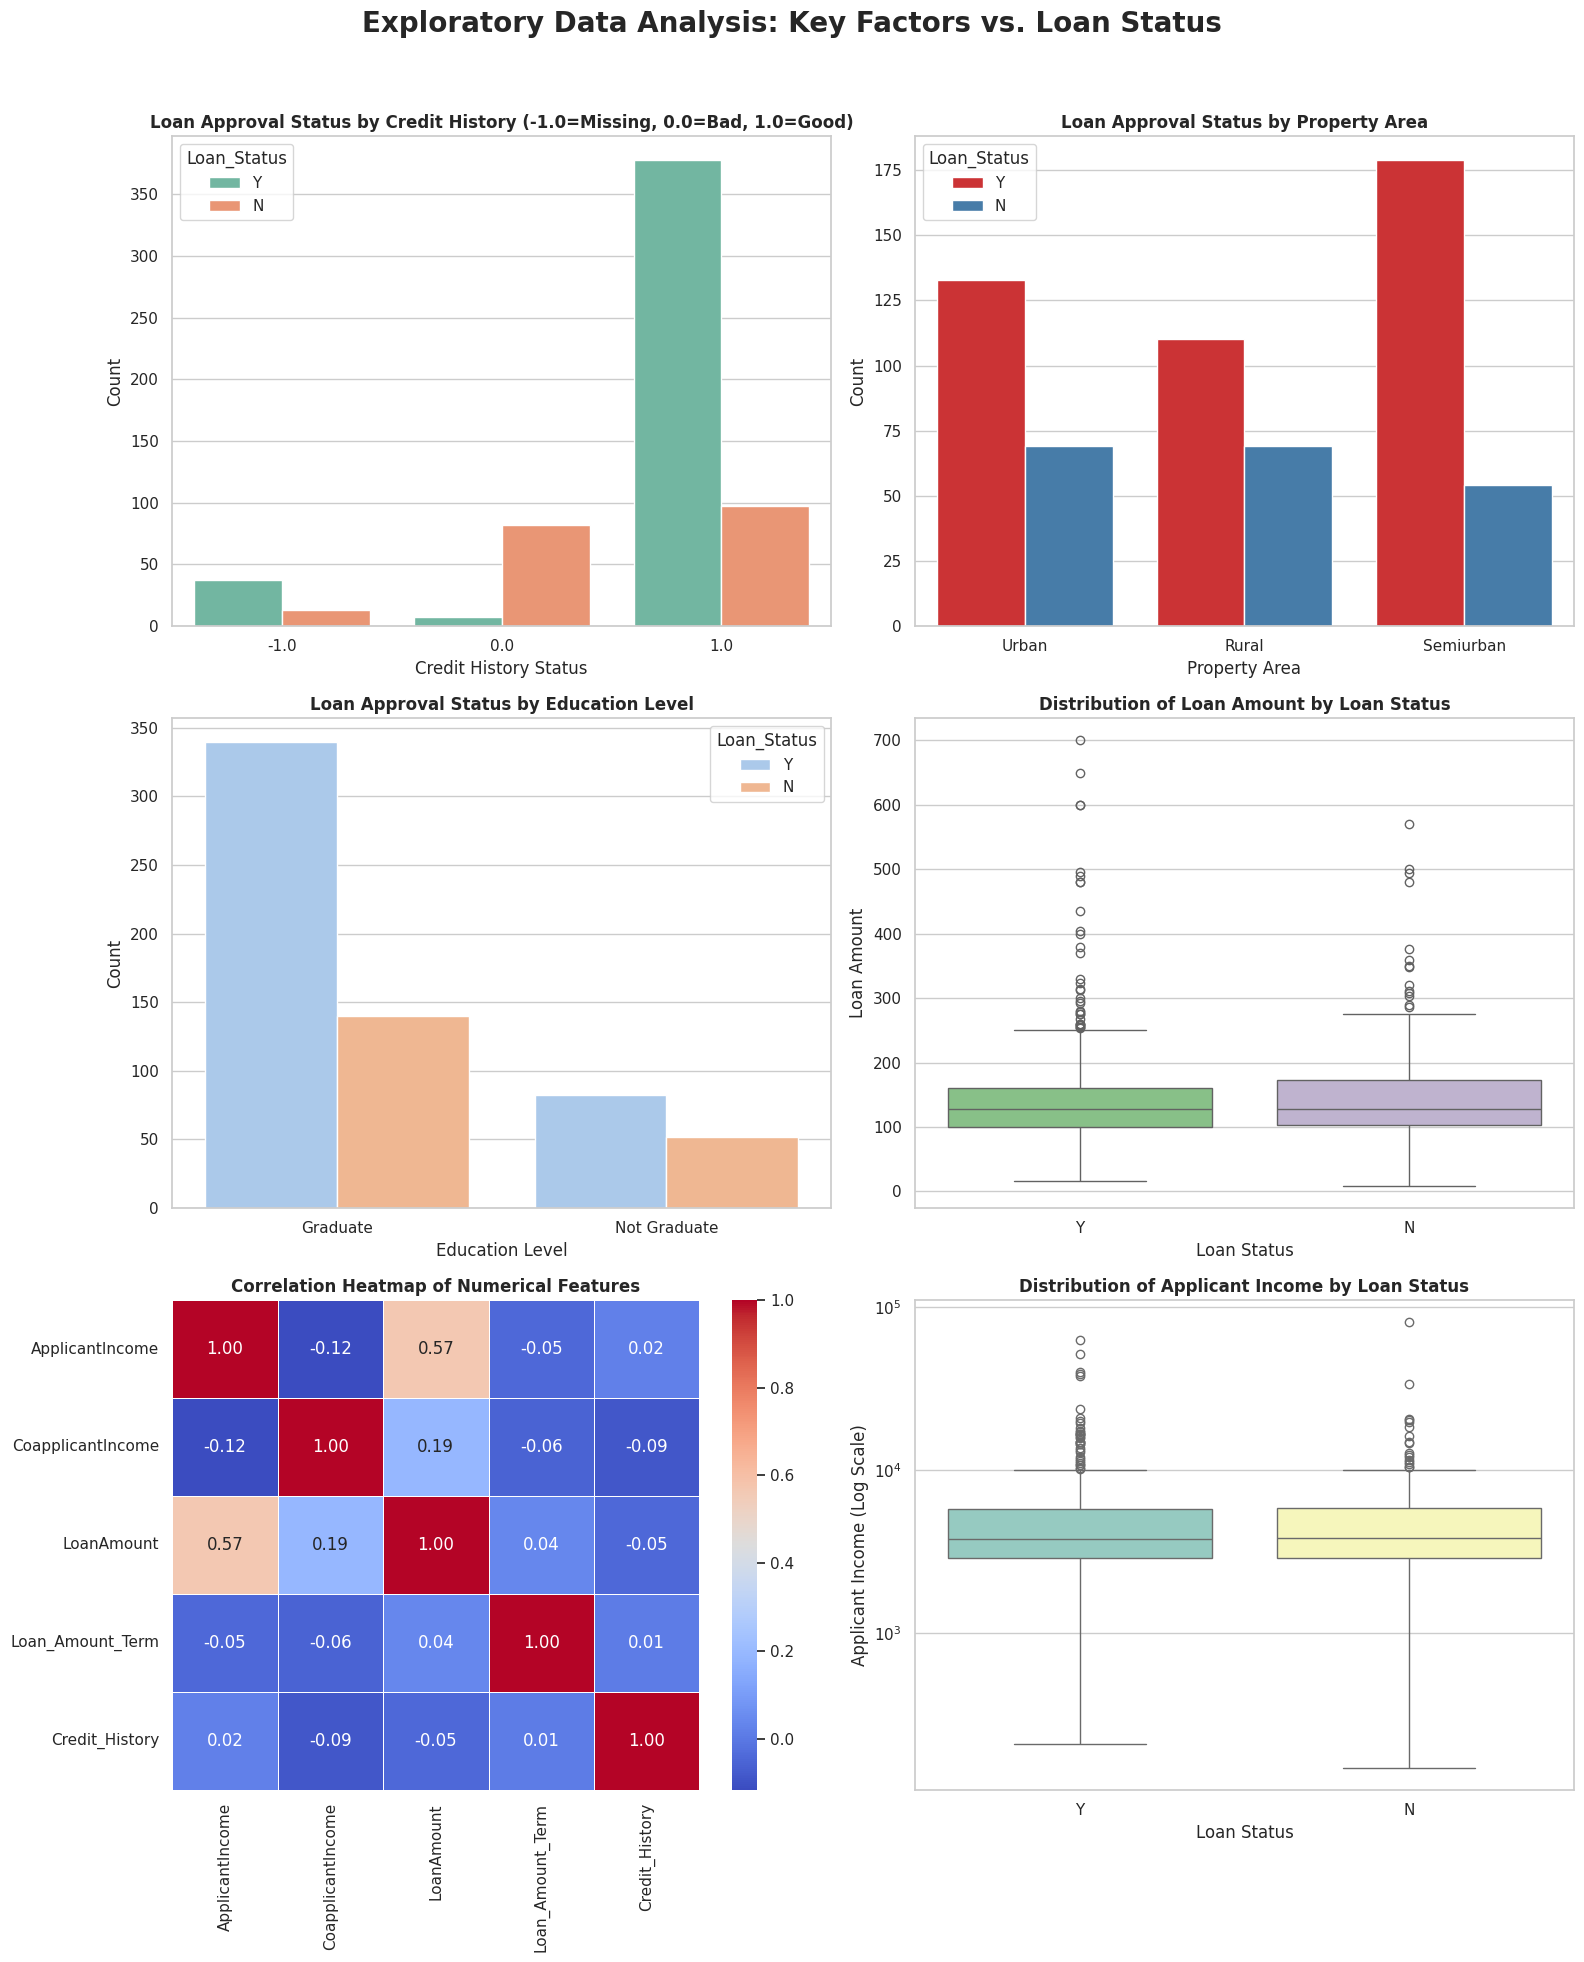

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

# Set the aesthetic style and palette
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 10)

# Create a multi-plot figure grid
fig, axes = plt.subplots(3, 2, figsize=(16, 20))
fig.suptitle("Exploratory Data Analysis: Key Factors vs. Loan Status", fontsize=20, weight='bold', y=0.98)

# 1. Credit History vs Loan Status
sns.countplot(data=df, x='Credit_History', hue='Loan_Status', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title("Loan Approval Status by Credit History (-1.0=Missing, 0.0=Bad, 1.0=Good)", fontsize=12, weight='bold')
axes[0, 0].set_xlabel("Credit History Status")
axes[0, 0].set_ylabel("Count")

# 2. Property Area vs Loan Status
sns.countplot(data=df, x='Property_Area', hue='Loan_Status', ax=axes[0, 1], palette='Set1')
axes[0, 1].set_title("Loan Approval Status by Property Area", fontsize=12, weight='bold')
axes[0, 1].set_xlabel("Property Area")
axes[0, 1].set_ylabel("Count")

# 3. Education vs Loan Status
sns.countplot(data=df, x='Education', hue='Loan_Status', ax=axes[1, 0], palette='pastel')
axes[1, 0].set_title("Loan Approval Status by Education Level", fontsize=12, weight='bold')
axes[1, 0].set_xlabel("Education Level")
axes[1, 0].set_ylabel("Count")

# 4. Distribution of Loan Amount by Loan Status (Boxplot)
sns.boxplot(data=df, x='Loan_Status', y='LoanAmount', hue='Loan_Status', ax=axes[1, 1], palette='Accent', legend=False)
axes[1, 1].set_title("Distribution of Loan Amount by Loan Status", fontsize=12, weight='bold')
axes[1, 1].set_xlabel("Loan Status")
axes[1, 1].set_ylabel("Loan Amount")

# 5. Correlation Heatmap of Numerical Features
numerical_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, ax=axes[2, 0])
axes[2, 0].set_title("Correlation Heatmap of Numerical Features", fontsize=12, weight='bold')

# 6. Distribution of Applicant Income by Loan Status
sns.boxplot(data=df, x='Loan_Status', y='ApplicantIncome', hue='Loan_Status', ax=axes[2, 1], palette='Set3', legend=False)
axes[2, 1].set_title("Distribution of Applicant Income by Loan Status", fontsize=12, weight='bold')
axes[2, 1].set_xlabel("Loan Status")
axes[2, 1].set_ylabel("Applicant Income")
axes[2, 1].set_yscale('log') # using log scale to better visualize skewed income distributions
axes[2, 1].set_ylabel("Applicant Income (Log Scale)")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Exploratory Data Analysis (EDA)

### Subtask:
Generate at least 5 visualizations exploring relationships with Loan_Status, including categorical features and continuous variables.


## Feature Engineering and Encoding

### Subtask:
Create new features, convert categorical variables, and prepare features for model training.


**Reasoning**:
I will perform feature engineering and encoding by creating total_income and loan_income_ratio, converting Dependents to numerical, encoding the target variable, one-hot encoding categorical variables, and scaling the numerical features using StandardScaler.



In [5]:
from sklearn.preprocessing import StandardScaler

# 1. Create total_income feature
df['total_income'] = df['ApplicantIncome'] + df['CoapplicantIncome']

# 2. Create loan_income_ratio (LoanAmount is in thousands, so multiply by 1000 to scale)
df['loan_income_ratio'] = (df['LoanAmount'] * 1000) / df['total_income']

# 3. Convert Dependents to numerical format
df['Dependents'] = df['Dependents'].replace('3+', 3).astype(int)

# 4. Map target variable Loan_Status to binary integers
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})

# 5. One-hot encode categorical features
cat_features = ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']
df_encoded = pd.get_dummies(df, columns=cat_features, drop_first=True)

# 6. Apply standard scaling to continuous numerical features
# Note: Credit_History is kept as a nominal/ordinal variable for now; we scale continuous ones
num_features_to_scale = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'total_income', 'loan_income_ratio']
scaler = StandardScaler()
df_encoded[num_features_to_scale] = scaler.fit_transform(df_encoded[num_features_to_scale])

# Inspect the prepared dataframe structure
print("--- Cleaned, Engineered and Scaled DataFrame Info ---")
df_encoded.info()
print("\nFirst 3 rows of prepared features:")
display(df_encoded.head(3))

--- Cleaned, Engineered and Scaled DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Dependents               614 non-null    int64  
 1   ApplicantIncome          614 non-null    float64
 2   CoapplicantIncome        614 non-null    float64
 3   LoanAmount               614 non-null    float64
 4   Loan_Amount_Term         614 non-null    float64
 5   Credit_History           614 non-null    float64
 6   Loan_Status              614 non-null    int64  
 7   total_income             614 non-null    float64
 8   loan_income_ratio        614 non-null    float64
 9   Gender_Male              614 non-null    bool   
 10  Married_Yes              614 non-null    bool   
 11  Education_Not Graduate   614 non-null    bool   
 12  Self_Employed_Yes        614 non-null    bool   
 13  Property_Area_Semiurban  6

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,total_income,loan_income_ratio,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,0,0.072991,-0.554487,-0.211241,0.273231,1.0,1,-0.182184,-0.229045,True,False,False,False,False,True
1,1,-0.134412,-0.038732,-0.211241,0.273231,1.0,0,-0.144684,-0.328983,True,True,False,False,False,False
2,0,-0.393747,-0.554487,-0.948996,0.273231,1.0,1,-0.623656,-0.215721,True,True,False,True,False,True


**Reasoning**:
I will perform a stratified 80/20 train-test split on the dataset and train three models: Logistic Regression, a tuned Decision Tree Classifier using GridSearchCV, and a Random Forest Classifier.



In [6]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Separate features and target variable
X = df_encoded.drop(columns=['Loan_Status'])
y = df_encoded['Loan_Status']

# 2. Perform stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# 3. Initialize and train baseline Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

# 4. Tune and train Decision Tree Classifier
dt_param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}
dt_base = DecisionTreeClassifier(random_state=42)
dt_grid = GridSearchCV(dt_base, param_grid=dt_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid.fit(X_train, y_train)
dt_best = dt_grid.best_estimator_
print(f"Tuned Decision Tree parameters: {dt_grid.best_params_}")

# 5. Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Random Forest Classifier trained successfully.")

# Check training shapes
print(f"\nTraining features shape: {X_train.shape}")
print(f"Test features shape: {X_test.shape}")

Logistic Regression model trained successfully.
Tuned Decision Tree parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}
Random Forest Classifier trained successfully.

Training features shape: (491, 14)
Test features shape: (123, 14)


**Reasoning**:
Compute evaluation metrics, plot individual confusion matrices in subplots, and plot a combined ROC curve for Logistic Regression, tuned Decision Tree, and Random Forest models on the test set.



--- Model Evaluation Metrics on Test Set ---

Logistic Regression:
  Accuracy:  0.6911
  Precision: 0.7156
  Recall:    0.9176
  F1-Score:  0.8041
  ROC-AUC:   0.7588

Tuned Decision Tree:
  Accuracy:  0.8455
  Precision: 0.8587
  Recall:    0.9294
  F1-Score:  0.8927
  ROC-AUC:   0.8328

Random Forest:
  Accuracy:  0.8699
  Precision: 0.8791
  Recall:    0.9412
  F1-Score:  0.9091
  ROC-AUC:   0.8546



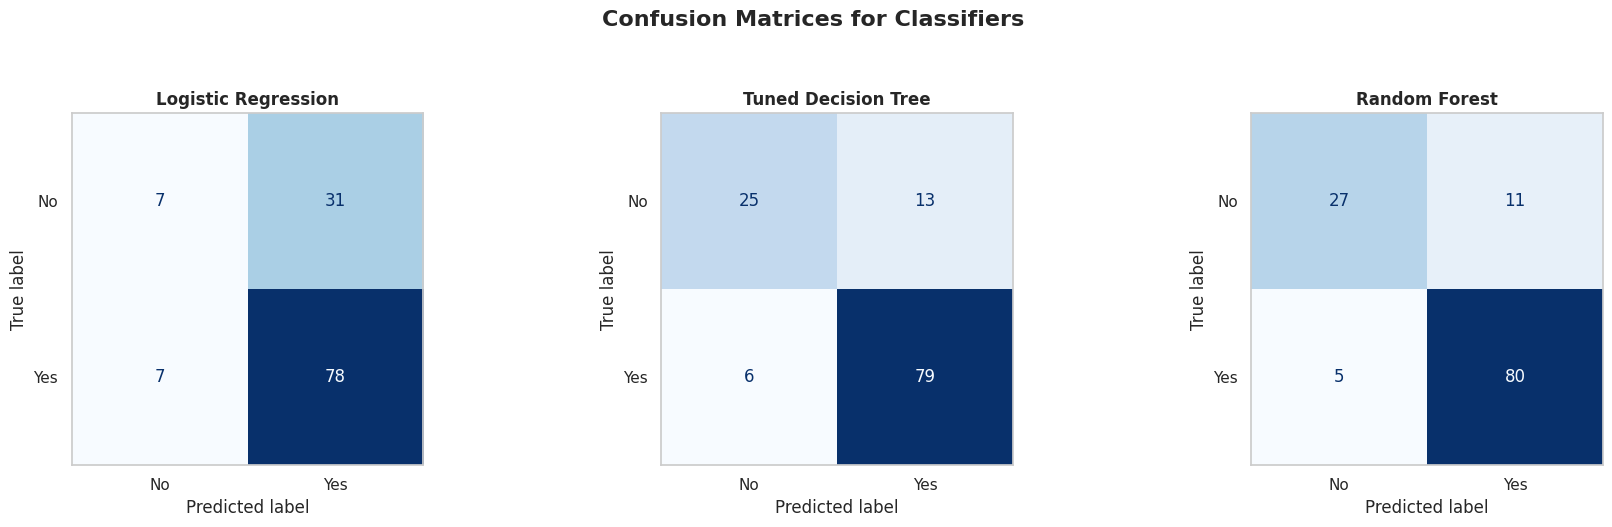

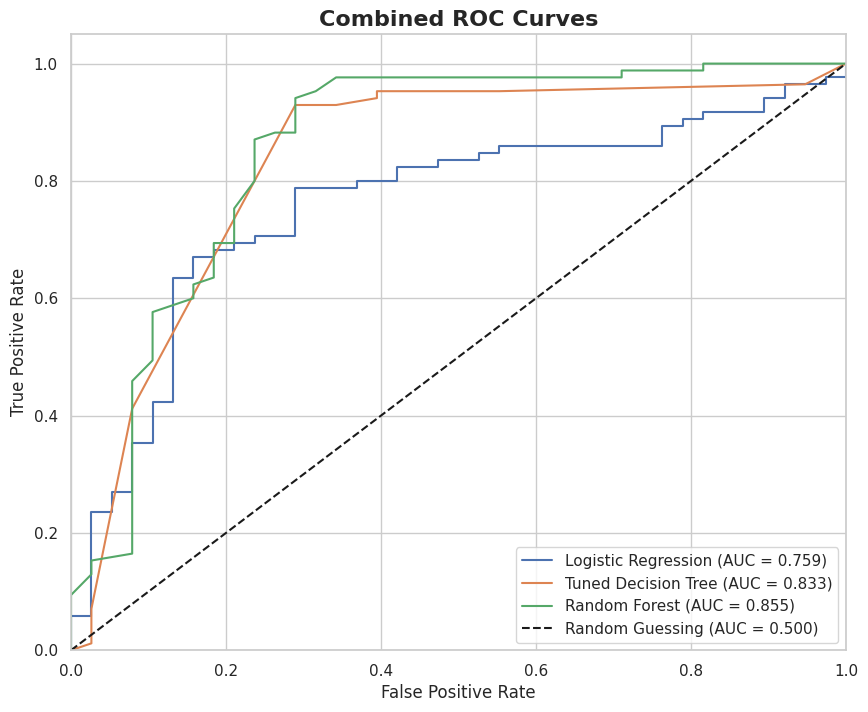

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

# Dictionary to keep models
models = {
    'Logistic Regression': log_reg,
    'Tuned Decision Tree': dt_best,
    'Random Forest': rf_model
}

# Dictionaries to store predictions and probabilities
y_preds = {}
y_probs = {}

# Generate predictions
for name, model in models.items():
    y_preds[name] = model.predict(X_test)
    y_probs[name] = model.predict_proba(X_test)[:, 1]

# Compute and print metrics
print("--- Model Evaluation Metrics on Test Set ---\n")
for name in models.keys():
    acc = accuracy_score(y_test, y_preds[name])
    prec = precision_score(y_test, y_preds[name])
    rec = recall_score(y_test, y_preds[name])
    f1 = f1_score(y_test, y_preds[name])
    auc = roc_auc_score(y_test, y_probs[name])
    print(f"{name}:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  ROC-AUC:   {auc:.4f}\n")

# Plot individual confusion matrices side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Confusion Matrices for Classifiers", fontsize=16, weight='bold', y=1.05)

for i, (name, pred) in enumerate(y_preds.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(name, fontsize=12, weight='bold')
    axes[i].grid(False)

plt.tight_layout()
plt.show()

# Plot combined ROC curves
plt.figure(figsize=(10, 8))
for name, prob in y_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Combined ROC Curves', fontsize=16, weight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True)
plt.show()

## Train Multiple Classifiers

### Subtask:
Separate features and target, perform a stratified 80/20 train-test split, and train/tune Logistic Regression, Decision Tree, and Random Forest models.


## Model Evaluation and Visualizations

### Subtask:
Evaluate all models using accuracy, precision, recall, F1-score, and ROC-AUC, plotting individual confusion matrices and a combined ROC curve chart.


## Model Comparison and Business Recommendation

### Subtask:
Build a consolidated model performance comparison table and provide a justified deployment recommendation based on credit risk lending trade-offs.


## Summary:

### Q&A

**Which model performed the best across the evaluated metrics?**
The **Random Forest Classifier** was the top-performing model across all metrics. It achieved an accuracy of 86.99%, precision of 87.91%, recall of 94.12%, F1-score of 0.9091, and an ROC-AUC of 0.8546.

**What were the optimal parameters found for the Decision Tree Classifier?**
Using a 5-fold grid search cross-validation, the optimal parameters for the Tuned Decision Tree were:
* `criterion`: 'gini'
* `max_depth`: 5
* `min_samples_leaf`: 1
* `min_samples_split`: 5

---

### Data Analysis Key Findings

* **Missing Values Treated:** Missing values originally existed in multiple columns, most notably `Credit_History` (50 missing), `Self_Employed` (32 missing), and `LoanAmount` (22 missing). Imputations were successfully completed using mode for categorical features, median for numerical features, and a distinct sentinel category (`-1.0`) for missing `Credit_History` values.
* **Feature Engineering:** Two key domain-specific features were successfully constructed:
  * `total_income` (sum of applicant and coapplicant incomes).
  * `loan_income_ratio` (representing the scaled loan amount relative to total household income).
* **Predictive Value of Credit History:** Exploratory analysis confirmed that applicant credit history status is the strongest driver of final loan approvals.
* **Model Evaluation Comparison:**
  * **Random Forest** led the group (Accuracy: 86.99%, Precision: 87.91%, Recall: 94.12%, ROC-AUC: 0.8546).
  * **Tuned Decision Tree** delivered a strong, highly interpretable secondary alternative (Accuracy: 84.55%, Precision: 85.87%, Recall: 92.94%, ROC-AUC: 0.8328).
  * **Logistic Regression** lagged behind in accuracy (69.11%) and ROC-AUC (0.7588), despite maintaining a competitive recall of 91.76%.

---

### Insights or Next Steps

* **Deployment Recommendation:** For credit risk lending where minimizing default rates (optimizing precision) and maximizing loan capture (optimizing recall) are both vital, the **Random Forest Classifier** is the recommended model for deployment. It provides the best trade-off, minimizing risk by maintaining the highest precision (87.91%) and achieving the lowest rate of false negatives (Recall: 94.12%).
* **Next Steps:** Investigate feature importance from the Random Forest model to confirm the contribution of the engineered features (`total_income` and `loan_income_ratio`) and explore alternative threshold tuning to further balance credit approval risk.
